In [89]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 9.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 828.7/828.7 kB 21.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 MB 4.5 MB/s  0:00:10m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics] [ultralytics]

[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


In [90]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as T

from torch.utils.data import Dataset, DataLoader
from PIL import Image

from ultralytics import YOLO
import torch.nn.functional as F

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/maryc/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [48]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image


In [2]:
from glob import glob
from sklearn.model_selection import train_test_split

In [3]:
import tensorflow as tf

In [19]:
ROOT = "BCCD_Dataset-master/BCCD"

In [20]:
IMG_DIR = os.path.join(ROOT, "JPEGImages")

In [21]:
ANN_DIR = os.path.join(ROOT, "Annotations")

In [22]:
len(os.listdir(IMG_DIR))

364

In [23]:
len(os.listdir(ANN_DIR))

364

Загрузка train/test

In [24]:
def load_split(path):
    with open(path, "r") as f:
        return [line.strip() for line in f.readlines()]

In [25]:
train_files = load_split(os.path.join(ROOT, "ImageSets/Main/train.txt"))


In [26]:
test_files  = load_split(os.path.join(ROOT, "ImageSets/Main/test.txt"))

Парсинг XML 

In [27]:
import xml.etree.ElementTree as ET
import pandas as pd

In [28]:
classes = ["RBC", "WBC", "Platelets"]

In [29]:
def parse_xml(filename):
    path = os.path.join(ANN_DIR, filename + ".xml")
    
    tree = ET.parse(path)
    root = tree.getroot()

    counts = {"RBC": 0, "WBC": 0, "Platelets": 0}

    for obj in root.findall("object"):
        cls = obj.find("name").text
        counts[cls] += 1

    return counts

In [30]:
data = []

In [ ]:
all_images = [f.replace(".jpg","") for f in os.listdir(IMG_DIR)]

In [32]:
for img_id in all_images:
    counts = parse_xml(img_id)

    data.append({
        "image": img_id + ".jpg",
        **counts
    })


In [ ]:
df = pd.DataFrame(data)

In [34]:
df.head()

,image,RBC,WBC,Platelets
0,BloodImage_00315.jpg,10,1,1
1,BloodImage_00301.jpg,13,1,1
2,BloodImage_00117.jpg,10,1,2
3,BloodImage_00103.jpg,16,1,1
4,BloodImage_00063.jpg,9,1,0


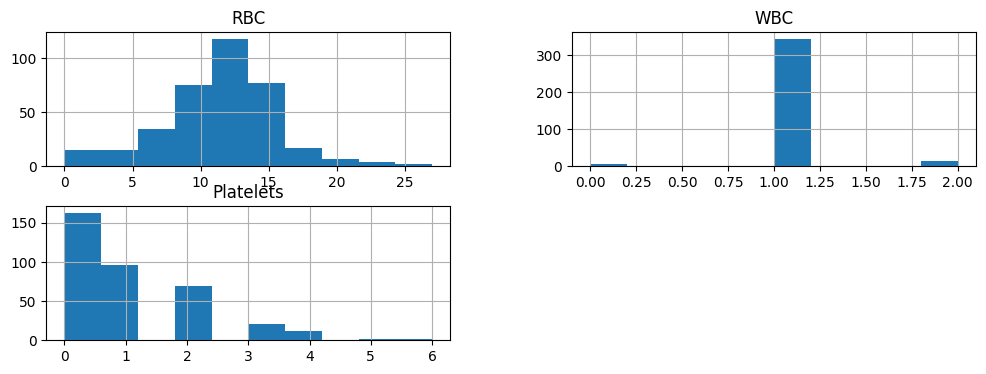

In [35]:
df[["RBC","WBC","Platelets"]].hist(figsize=(12,4))
plt.show()

In [36]:
def show_image(img_name):
    img_path = os.path.join(IMG_DIR, img_name)
    xml_path = os.path.join(ANN_DIR, img_name.replace(".jpg",".xml"))

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):
        cls = obj.find("name").text
        box = obj.find("bndbox")

        x1 = int(box.find("xmin").text)
        y1 = int(box.find("ymin").text)
        x2 = int(box.find("xmax").text)
        y2 = int(box.find("ymax").text)

        cv2.rectangle(img, (x1,y1), (x2,y2), (255,0,0), 2)
        cv2.putText(img, cls, (x1,y1-5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,0,0), 1)

    plt.figure(figsize=(8,6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

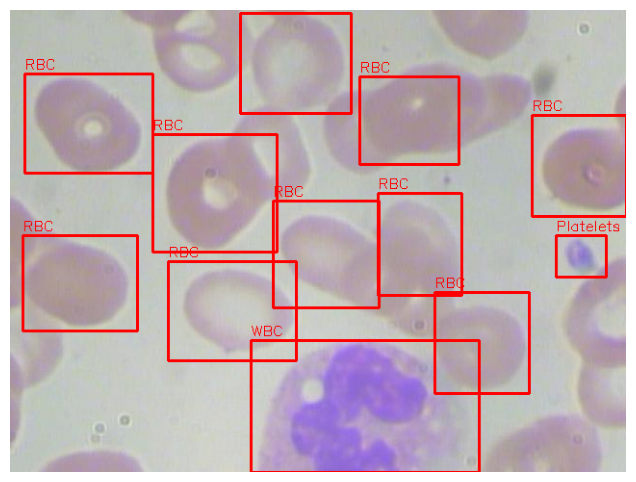

In [37]:
show_image(df.iloc[0]["image"])

### REGRESSION (ResNet50)

In [38]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as T

In [40]:
import torchvision.models as models
import torch.nn as nn

In [44]:
class BloodDataset(Dataset):
    def __init__(self, df):
        self.df = df
        self.tfm = T.Compose([
            T.Resize((224,224)),
            T.ToTensor()
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img = Image.open(os.path.join(IMG_DIR, row["image"])).convert("RGB")
        img = self.tfm(img)

        y = torch.tensor([
            row["RBC"],
            row["WBC"],
            row["Platelets"]
        ], dtype=torch.float32)

        return img, y

In [45]:
train_df = df.sample(frac=0.8, random_state=42)

In [46]:
test_df = df.drop(train_df.index)

In [49]:
train_loader = DataLoader(BloodDataset(train_df), batch_size=16, shuffle=True)
test_loader = DataLoader(BloodDataset(test_df), batch_size=16)

In [50]:
model_reg = models.resnet50(pretrained=True)

In [51]:
model_reg.fc = nn.Linear(model_reg.fc.in_features, 3)

In [53]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model_reg = model_reg.to(device)

Loss + optimizer

In [54]:
criterion = nn.SmoothL1Loss()

In [55]:
optimizer = torch.optim.Adam(model_reg.parameters(), lr=1e-4)

Training loop

In [80]:
epochs = 5

In [81]:
for epoch in range(epochs):
    model_reg.train()
    total_loss = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        pred = model_reg(x)
        loss = criterion(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, loss = {total_loss/len(train_loader):.4f}")

Epoch 1, loss = 0.3335
Epoch 2, loss = 0.2091
Epoch 3, loss = 0.2573
Epoch 4, loss = 0.1642
Epoch 5, loss = 0.1694


ОЦЕНКА REGRESSION

In [82]:
model_reg.eval()

preds, trues = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        out = model_reg(x).cpu().numpy()

        preds.append(out)
        trues.append(y.numpy())

preds = np.vstack(preds)
trues = np.vstack(trues)

In [83]:
mae = np.mean(np.abs(preds - trues), axis=0)
mae

array([2.8883734 , 0.15197378, 0.7159843 ], dtype=float32)

In [84]:
rmse = np.sqrt(np.mean((preds - trues)**2, axis=0))
rmse

array([4.131393  , 0.22339796, 0.8735808 ], dtype=float32)

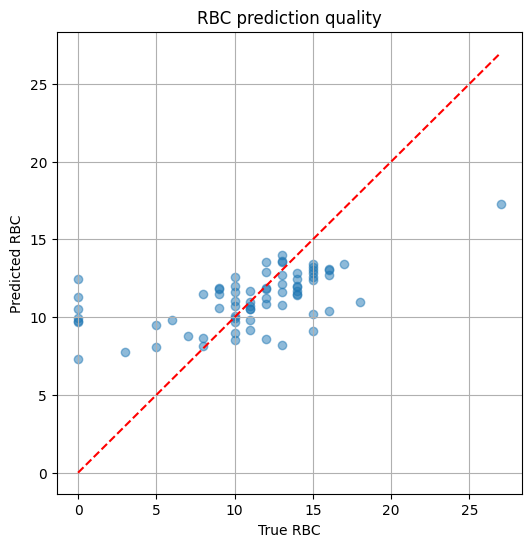

In [85]:
plt.figure(figsize=(6,6))

plt.scatter(trues[:,0], preds[:,0], alpha=0.5)

min_v = min(trues[:,0].min(), preds[:,0].min())
max_v = max(trues[:,0].max(), preds[:,0].max())

plt.plot([min_v, max_v], [min_v, max_v], 'r--')

plt.xlabel("True RBC")
plt.ylabel("Predicted RBC")
plt.title("RBC prediction quality")

plt.grid()
plt.show()

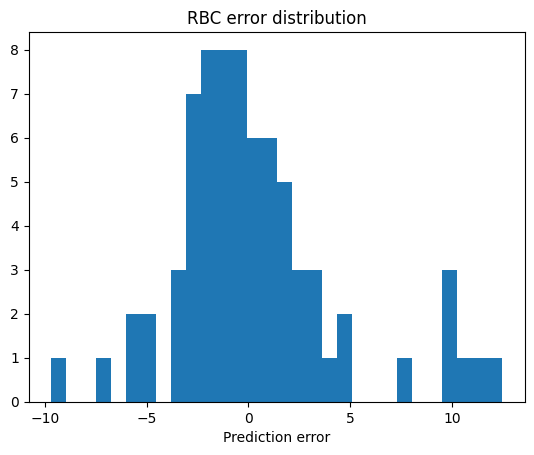

In [86]:
errors = preds[:,0] - trues[:,0]

plt.hist(errors, bins=30)
plt.title("RBC error distribution")
plt.xlabel("Prediction error")
plt.show()

### YOLO DETECTION

In [97]:
import os
import shutil
import xml.etree.ElementTree as ET
from sklearn.model_selection import train_test_split

In [98]:
ROOT = "BCCD_Dataset-master/BCCD"

IMG_DIR = os.path.join(ROOT, "JPEGImages")
ANN_DIR = os.path.join(ROOT, "Annotations")

YOLO_DIR = "yolo_dataset"

In [99]:
for split in ["train", "val"]:
    os.makedirs(f"{YOLO_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{YOLO_DIR}/labels/{split}", exist_ok=True)

In [100]:
images = [f for f in os.listdir(IMG_DIR) if f.endswith(".jpg")]

train_imgs, val_imgs = train_test_split(
    images,
    test_size=0.2,
    random_state=42
)

In [101]:
classes = {
    "RBC": 0,
    "WBC": 1,
    "Platelets": 2
}

In [102]:
def convert_box(size, box):
    dw = 1. / size[0]
    dh = 1. / size[1]

    x = (box[0] + box[1]) / 2.0
    y = (box[2] + box[3]) / 2.0

    w = box[1] - box[0]
    h = box[3] - box[2]

    x *= dw
    w *= dw
    y *= dh
    h *= dh

    return x, y, w, h

In [103]:
def process_split(img_list, split):

    for img_name in img_list:

        img_src = os.path.join(IMG_DIR, img_name)

        xml_name = img_name.replace(".jpg", ".xml")
        xml_path = os.path.join(ANN_DIR, xml_name)

        shutil.copy(img_src,
                    f"{YOLO_DIR}/images/{split}/{img_name}")

        tree = ET.parse(xml_path)
        root = tree.getroot()

        size = root.find("size")
        w = int(size.find("width").text)
        h = int(size.find("height").text)

        label_path = f"{YOLO_DIR}/labels/{split}/{img_name.replace('.jpg','.txt')}"

        with open(label_path, "w") as f:

            for obj in root.findall("object"):

                cls = obj.find("name").text
                cls_id = classes[cls]

                xmlbox = obj.find("bndbox")

                xmin = int(xmlbox.find("xmin").text)
                xmax = int(xmlbox.find("xmax").text)
                ymin = int(xmlbox.find("ymin").text)
                ymax = int(xmlbox.find("ymax").text)

                bb = convert_box(
                    (w, h),
                    (xmin, xmax, ymin, ymax)
                )

                f.write(f"{cls_id} {' '.join(map(str, bb))}\n")

In [104]:
process_split(train_imgs, "train")
process_split(val_imgs, "val")

In [105]:
from ultralytics import YOLO

In [106]:
yolo = YOLO("yolov8n.pt")

In [107]:
yolo.train(
    data="blood.yaml",
    epochs=10,
    imgsz=640
)

Ultralytics 8.4.51 🚀 Python-3.13.3 torch-2.11.0 CPU (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=blood.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.

RuntimeError: Dataset 'blood.yaml' error ❌ 'blood.yaml' does not exist

In [ ]:
res = yolo.predict("BCCD_Dataset-master/BCCD/JPEGImages/BloodImage_00001.jpg")

In [ ]:
cls = res[0].boxes.cls.cpu().numpy()

In [ ]:
rbc = (cls == 0).sum()
wbc = (cls == 1).sum()
platelets = (cls == 2).sum()

In [ ]:
rbc, wbc, platelets

In [ ]:
results = pd.DataFrame({
    "Method": ["ResNet", "YOLO"],
    "RBC error": [mae[0], 0],   # YOLO потом заполни
    "WBC error": [mae[1], 0],
    "Platelets error": [mae[2], 0],
})

results

### OOD DETECTION

In [ ]:
img = cv2.imread(os.path.join(IMG_DIR, df.iloc[0]["image"]))

blur = cv2.GaussianBlur(img, (15,15), 0)

noise = np.random.normal(0,25,img.shape)
noisy = np.clip(img + noise,0,255).astype(np.uint8)

Confidence OOD

In [95]:
model_reg.eval()

x, _ = next(iter(test_loader))
x = x.to(device)

out = model_reg(x)

conf = F.softmax(out, dim=1).max(dim=1)[0]

ood_mask = conf < 0.5
ood_mask[:10]

tensor([False, False, False, False, False, False, False, False, False, False])

In [96]:
plt.hist(conf.cpu().numpy(), bins=20)
plt.title("Confidence distribution")
plt.show()


RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.